# **Authors**

*   Kumar Jayant
*   Dhruv Lalani

# **Notions of distance - Part 1**


Import required packages

In [2]:
!pip install ydata_profiling

In [3]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics.pairwise import pairwise_distances
from ydata_profiling import ProfileReport
from sklearn.metrics.pairwise import pairwise_distances, cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
# Suppress all warnings completely
warnings.filterwarnings('ignore')

/tmp/ipykernel_89078/3209920733.py:8: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


##### Step 1: Data Preprocessing to ready the data for analysis

1. Ingest the ola dataset.
2. Data profiling
3. Data cleansing (dropping features not needed for analysis)
4. Data imputation
5. Data Encoding for categorical features
6. Short Description of the final features for familiarity with the dataset


Ingesting the dataset

In [4]:
# Load the data
file_path = "/content/ola.csv"
ola_df = pd.read_csv(file_path, encoding='ISO-8859-1')
ola_df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for Cancelling by Customer,Cancelled Rides by Driver,Reason for Cancelling by Driver,Incomplete Rides,Incomplete Rides Reason,Booking Value,Payment Method,Ride Distance,Driver Ratings,Customer Rating
0,28/01/2024,6:00:00,CNR1721175,Success,329258,Auto,Area-3,Area-2,5.42,18.46,...,NaN,0,NaN,0,NaN,868.06,Wallet,28.5,4.4,4.4
1,26/01/2024,3:00:00,CNR2871422,Cancelled by Driver,201414,Mini,Area-7,Area-6,NaN,NaN,...,NaN,1,The customer was coughing/sick,0,NaN,NaN,NaN,NaN,NaN,NaN
2,15/01/2024,16:00:00,CNR6875935,Cancelled by Driver,301629,Bike,Area-40,Area-24,NaN,NaN,...,NaN,1,Personal & Car related issues,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2/1/24,22:00:00,CNR6798834,Cancelled by Driver,319684,Prime Sedan,Area-11,Area-24,NaN,NaN,...,NaN,1,The customer was coughing/sick,0,NaN,NaN,NaN,NaN,NaN,NaN
4,30/01/2024,22:00:00,CNR9661713,Incomplete,330283,Bike,Area-41,Area-45,NaN,NaN,...,NaN,0,NaN,1,Other Issue,NaN,NaN,NaN,NaN,NaN


Profiling the dataset

In [5]:
ola_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 21 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Date                               49999 non-null  object 
 1   Time                               49999 non-null  object 
 2   Booking ID                         49999 non-null  object 
 3   Booking Status                     49999 non-null  object 
 4   Customer ID                        49999 non-null  int64  
 5   Vehicle Type                       49999 non-null  object 
 6   Pickup Location                    49999 non-null  object 
 7   Drop Location                      49999 non-null  object 
 8   Avg VTAT                           33484 non-null  float64
 9   Avg CTAT                           33484 non-null  float64
 10  Cancelled  by Customer             49999 non-null  int64  
 11  Reason for Cancelling by Customer  3799 non-null   obj

**Data Cleansing**

For the purpose of this exercise we will drop features not required.

Following features shall be dropped.


1. Date
2. Time
3. Booking ID
4. Booking Status
5. Cancelled  by Customer
6. Reason for Cancelling by Customer
7. Incomplete Rides
8. Incomplete Rides Reason
9. Cancelled Rides by Driver
10. Reason for Cancelling by Driver



In [6]:
ola_df.drop(columns=['Date','Time','Booking ID','Booking Status','Cancelled  by Customer',
                     'Reason for Cancelling by Customer','Incomplete Rides','Incomplete Rides Reason',
                     'Cancelled Rides by Driver','Reason for Cancelling by Driver'], inplace=True)

In [7]:
# convert Customer ID to object datatype
ola_df['Customer ID'] = ola_df['Customer ID'].astype(str)

In [8]:
ola_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49999 entries, 0 to 49998
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      49999 non-null  object 
 1   Vehicle Type     49999 non-null  object 
 2   Pickup Location  49999 non-null  object 
 3   Drop Location    49999 non-null  object 
 4   Avg VTAT         33484 non-null  float64
 5   Avg CTAT         33484 non-null  float64
 6   Booking Value    33484 non-null  float64
 7   Payment Method   33484 non-null  object 
 8   Ride Distance    33484 non-null  float64
 9   Driver Ratings   33484 non-null  float64
 10  Customer Rating  33484 non-null  float64
dtypes: float64(6), object(5)
memory usage: 4.2+ MB


**Data Imputation**

The following fields will be imputed for missing data.

**Numerical fields**

1. Avg VTAT
2. Avg CTAT
3. Booking Value
4. Ride Distance
5. Driver Ratings
6. Customer Rating

Logic for imputation - If there are multiple customer IDs for these fields then average of the customer IDs will be used for imputation else the previous row data shall be rolled over.

**Categorical field**

1. Payment Method

Logic for imputation - If there are multiple customer IDs for this field then max instance of the customer IDs will be used for imputation else the previous row data shall be rolled over.

In [9]:
# Imputing numerical features

ola_df['Avg VTAT'] = ola_df['Avg VTAT'].fillna(ola_df.groupby('Customer ID')['Avg VTAT'].transform('mean'))
ola_df['Avg VTAT'] = ola_df['Avg VTAT'].ffill().bfill()

ola_df['Avg CTAT'] = ola_df['Avg CTAT'].fillna(ola_df.groupby('Customer ID')['Avg CTAT'].transform('mean'))
ola_df['Avg CTAT'] = ola_df['Avg CTAT'].ffill().bfill()

ola_df['Booking Value'] = ola_df['Booking Value'].fillna(ola_df.groupby('Customer ID')['Booking Value'].transform('mean'))
ola_df['Booking Value'] = ola_df['Booking Value'].ffill().bfill()

ola_df['Ride Distance'] = ola_df['Ride Distance'].fillna(ola_df.groupby('Customer ID')['Ride Distance'].transform('mean'))
ola_df['Ride Distance'] = ola_df['Ride Distance'].ffill().bfill()

ola_df['Driver Ratings'] = ola_df['Driver Ratings'].fillna(ola_df.groupby('Customer ID')['Driver Ratings'].transform('mean'))
ola_df['Driver Ratings'] = ola_df['Driver Ratings'].ffill().bfill()

ola_df['Customer Rating'] = ola_df['Customer Rating'].fillna(ola_df.groupby('Customer ID')['Customer Rating'].transform('mean'))
ola_df['Customer Rating'] = ola_df['Customer Rating'].ffill().bfill()

In [10]:
# Imputing categorical feature

# Imputing categorical feature safely
ola_df['Payment Method'] = ola_df['Payment Method'].fillna(
    ola_df.groupby('Customer ID')['Payment Method'].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    )
)
ola_df['Payment Method'] = ola_df['Payment Method'].ffill().bfill()

In [11]:
ola_df.head()

,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,Booking Value,Payment Method,Ride Distance,Driver Ratings,Customer Rating
0,329258,Auto,Area-3,Area-2,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
1,201414,Mini,Area-7,Area-6,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
2,301629,Bike,Area-40,Area-24,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
3,319684,Prime Sedan,Area-11,Area-24,5.42,18.46,868.06,Wallet,28.5,4.4,4.4
4,330283,Bike,Area-41,Area-45,5.42,18.46,868.06,Wallet,28.5,4.4,4.4


Now we will consolidate the data at unique customer ID level.

Remember we are trying to find distance or similarity among customers, hence it is essential that we have one unique customer ID row

In [12]:
numeric_cols = [
    'Avg VTAT', 'Avg CTAT', 'Booking Value',
    'Ride Distance', 'Driver Ratings', 'Customer Rating'
]
for col in numeric_cols:
    # errors='coerce' turns any accidental text strings or bad formatting into real NaNs
    ola_df[col] = pd.to_numeric(ola_df[col], errors='coerce')


categorical_cols = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method']
for col in categorical_cols:
    ola_df[col] = ola_df[col].astype(str)

ola_df[categorical_cols] = ola_df[categorical_cols].replace({'nan': np.nan, 'None': np.nan})

final_aggregation_rules = {

    # Numerical features
    'Avg VTAT': 'mean',
    'Avg CTAT': 'mean',
    'Booking Value': 'mean',
    'Ride Distance': 'mean',
    'Driver Ratings': 'mean',
    'Customer Rating': 'mean',

    # Categorical features (Using custom lambda to safely extract the mode)
    'Vehicle Type': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Pickup Location': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Drop Location': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
    'Payment Method': lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan,
}

df_ola_cust_profile = ola_df.groupby('Customer ID').agg(final_aggregation_rules)

# Ensuring that categorical variables in no case carry nan values
categorical_cols = ['Vehicle Type', 'Pickup Location', 'Drop Location', 'Payment Method']
df_ola_cust_profile[categorical_cols] = df_ola_cust_profile[categorical_cols].ffill().bfill()

# Resetting the index
df_ola_cust_profile = df_ola_cust_profile.reset_index()

##### Step 2: Encoding data

'Vehicle Type' is an ordinal variable hence it will be 'label encoded'. We will explicitly decide the label for each value since we understand the hirerachy/class of the vehicle.

'Pickup Location', 'Drop Location', and 'Payment Method' are nominal variables hence will go through One hot encoding technique.

In [13]:
# Finding number of unique values in the 'Vehicle Type' feature

unique_vehicles = df_ola_cust_profile['Vehicle Type'].unique()
print("Unique Vehicle Types:")
print(unique_vehicles)

Unique Vehicle Types:
['Auto' 'Mini' 'Prime Plus' 'eBike' 'Prime SUV' 'Prime Sedan' 'Bike']


In [14]:
# Encoding vehicle type using label encoding

vehicle_ordinal_map = {
    'eBike': 0,
    'Bike': 1,
    'Auto': 2,
    'Mini': 3,
    'Prime Sedan': 4,
    'Prime Plus': 5,
    'Prime SUV': 6
}

# Apply the explicit mapping to your customer profile dataframe
df_ola_cust_profile['Vehicle Type_Encoded'] = df_ola_cust_profile['Vehicle Type'].map(vehicle_ordinal_map)

In [15]:
# 'Pickup Location', 'Drop Location', and 'Payment Method' to go through One hot encoding (OHE) technique

nominal_cols = ['Payment Method', 'Pickup Location', 'Drop Location']

# In-place transformation of the dataframe
# This encodes the nominal_cols, drops them, and appends the new OHE columns to all your other features

df_ola_cust_profile = pd.get_dummies(
    df_ola_cust_profile,
    columns=nominal_cols,
    dtype=float,
    drop_first=False
)

In [16]:
# Drop original column and keep only the encoded columns. OHE drops original column by itself. We will need to do this step for label encoding.

df_ola_cust_profile.drop(columns=['Vehicle Type'], inplace=True)

In [17]:
df_ola_cust_profile.columns

Index(['Customer ID', 'Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance',
       'Driver Ratings', 'Customer Rating', 'Vehicle Type_Encoded',
       'Payment Method_Card', 'Payment Method_Cash',
       ...
       'Drop Location_Area-46', 'Drop Location_Area-47',
       'Drop Location_Area-48', 'Drop Location_Area-49',
       'Drop Location_Area-5', 'Drop Location_Area-50', 'Drop Location_Area-6',
       'Drop Location_Area-7', 'Drop Location_Area-8', 'Drop Location_Area-9'],
      dtype='object', length=112)

In [18]:
df_ola_cust_profile.head()

,Customer ID,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Vehicle Type_Encoded,Payment Method_Card,Payment Method_Cash,...,Drop Location_Area-46,Drop Location_Area-47,Drop Location_Area-48,Drop Location_Area-49,Drop Location_Area-5,Drop Location_Area-50,Drop Location_Area-6,Drop Location_Area-7,Drop Location_Area-8,Drop Location_Area-9
0,100001,17.83,20.58,278.52,26.48,3.9,4.1,2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,100059,12.73,7.50,795.82,48.41,3.9,4.2,3,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100090,10.14,19.37,240.53,3.17,4.7,4.7,2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100097,12.19,10.27,678.06,18.18,3.2,3.5,3,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,100119,8.57,25.09,1458.82,17.10,3.4,3.1,2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
print(list(df_ola_cust_profile.columns))

['Customer ID', 'Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Vehicle Type_Encoded', 'Payment Method_Card', 'Payment Method_Cash', 'Payment Method_UPI', 'Payment Method_Wallet', 'Pickup Location_Area-1', 'Pickup Location_Area-10', 'Pickup Location_Area-11', 'Pickup Location_Area-12', 'Pickup Location_Area-13', 'Pickup Location_Area-14', 'Pickup Location_Area-15', 'Pickup Location_Area-16', 'Pickup Location_Area-17', 'Pickup Location_Area-18', 'Pickup Location_Area-19', 'Pickup Location_Area-2', 'Pickup Location_Area-20', 'Pickup Location_Area-21', 'Pickup Location_Area-22', 'Pickup Location_Area-23', 'Pickup Location_Area-24', 'Pickup Location_Area-25', 'Pickup Location_Area-26', 'Pickup Location_Area-27', 'Pickup Location_Area-28', 'Pickup Location_Area-29', 'Pickup Location_Area-3', 'Pickup Location_Area-30', 'Pickup Location_Area-31', 'Pickup Location_Area-32', 'Pickup Location_Area-33', 'Pickup Location_Area-34', 'Pickup Location_Ar

##### Step 3: Scaling data

The numerical data will now be scaled to ensure that Euclidean/Manhattan distance on raw features (like Trip_Fare vs Rider_Age) do not completely swamp the smaller numbers, making age irrelevant.

ideally, StandardScaler should to be used for Avg VTAT, Avg CTAT, Booking Value, Ride Distance and MinMaxScaler to be used for Driver Ratings, Customer Rating.

However Standard scaler creates a mix of positive-negative values which will completely skew the Canberra distance calculations hence we will use min-max scaling for this exercise.

In [20]:
scaler_minmax = MinMaxScaler()

# Define your features
features_to_scale = ['Avg VTAT', 'Avg CTAT', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating', 'Vehicle Type_Encoded']

# Create a temporary DataFrame with the scaled array, forcing it to use the exact same index
df_scaled_temp = pd.DataFrame(
    scaler_minmax.fit_transform(df_ola_cust_profile[features_to_scale]),
    columns=features_to_scale,
    index=df_ola_cust_profile.index
)

# Assign it back safely
df_ola_cust_profile[features_to_scale] = df_scaled_temp

In [21]:
#checking data sample

df_ola_cust_profile.head()

,Customer ID,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Vehicle Type_Encoded,Payment Method_Card,Payment Method_Cash,...,Drop Location_Area-46,Drop Location_Area-47,Drop Location_Area-48,Drop Location_Area-49,Drop Location_Area-5,Drop Location_Area-50,Drop Location_Area-6,Drop Location_Area-7,Drop Location_Area-8,Drop Location_Area-9
0,100001,0.885789,0.675172,0.117144,0.520000,0.45,0.55,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,100059,0.617368,0.224138,0.382440,0.967551,0.45,0.60,0.500000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100090,0.481053,0.633448,0.097661,0.044286,0.85,0.85,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100097,0.588947,0.319655,0.322047,0.350612,0.10,0.25,0.500000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,100119,0.398421,0.830690,0.722458,0.328571,0.20,0.05,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
print(df_ola_cust_profile.shape)

(48669, 112)


##### Final Step 4: Calculating pairwise distances and describing the dataset briefly

After data imputation and scaling we have clean dataset of 48669 unique ola customers.

The data set also has 112 columns. The dimensionality has increased manifold because we have do OHE (one hot encoding) for the following categorical variables.

1. Payment Method
2. Pickup Location
3. Drop Location

The following baseline features are being used to calculate pairwise distances between customers. The customers are being distinguished basis Customer ID.

1. Avg VTAT
2. Avg CTAT
3. Booking Value
4. Ride Distance
5. Driver Ratings
6. Customer Rating
7. Vehicle Type
8. Payment Method
9. Pickup Location
10. Drop Location

In [23]:
# Final code block to calculate pairwise distances

print(f"Total Customer Profiles Matrix Shape: {df_ola_cust_profile.shape} (Rows, Features)")

df_ola_cust_profile.head()

Total Customer Profiles Matrix Shape: (48669, 112) (Rows, Features)


,Customer ID,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Vehicle Type_Encoded,Payment Method_Card,Payment Method_Cash,...,Drop Location_Area-46,Drop Location_Area-47,Drop Location_Area-48,Drop Location_Area-49,Drop Location_Area-5,Drop Location_Area-50,Drop Location_Area-6,Drop Location_Area-7,Drop Location_Area-8,Drop Location_Area-9
0,100001,0.885789,0.675172,0.117144,0.520000,0.45,0.55,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,100059,0.617368,0.224138,0.382440,0.967551,0.45,0.60,0.500000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,100090,0.481053,0.633448,0.097661,0.044286,0.85,0.85,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,100097,0.588947,0.319655,0.322047,0.350612,0.10,0.25,0.500000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,100119,0.398421,0.830690,0.722458,0.328571,0.20,0.05,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


The final dataset has around unique 49,000 customer IDs. Finding pairwise distances among these customer IDs will be computaionally challenging.

We will preserve the cleansed dataset in a csv file.

We will use only 100 randomly selected customers from the massive dataset to calculate pairwise distances.

In [24]:
# preserving the clean dataset in a csv file.
df_ola_cust_profile.to_csv('final_ola_customer_profiles.csv', index=True)
print("Dataframe successfully exported")

Dataframe successfully exported


In [25]:
# Sample 100 profiles before moving into heavy distance matrices
df_sample = df_ola_cust_profile.sample(n=100, random_state=42)
df_sample

,Customer ID,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Vehicle Type_Encoded,Payment Method_Card,Payment Method_Cash,...,Drop Location_Area-46,Drop Location_Area-47,Drop Location_Area-48,Drop Location_Area-49,Drop Location_Area-5,Drop Location_Area-50,Drop Location_Area-6,Drop Location_Area-7,Drop Location_Area-8,Drop Location_Area-9
14916,379207,0.061579,0.032759,0.049341,0.625714,0.65,0.60,0.166667,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
47498,978650,0.934211,0.487586,0.346090,0.377347,0.45,0.75,0.000000,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27510,610167,0.824737,0.082414,0.614375,0.363061,0.75,0.25,0.666667,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
24050,547065,0.853158,0.004483,0.486256,0.007143,0.20,0.75,0.333333,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31951,691197,0.965263,0.851379,0.014283,0.712245,0.65,0.15,1.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46217,953941,0.317368,0.168621,0.162285,0.922653,0.60,1.00,0.333333,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8445,258562,0.843684,0.123103,0.797985,0.968980,0.00,0.55,1.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
36592,776024,0.692632,0.672069,0.271542,0.758367,0.95,0.65,0.500000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6720,225290,0.957895,0.373103,0.409862,0.917959,0.15,0.30,0.166667,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [26]:
# This line acts as a protective shield for the ID string while preserving row mappings
df_sample1 = df_sample.set_index('Customer ID')


# Convert numerical and scaled feature vectors into a NumPy array
X_final = df_sample1.to_numpy()

In [27]:
# final look
df_sample1.head()

,Avg VTAT,Avg CTAT,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Vehicle Type_Encoded,Payment Method_Card,Payment Method_Cash,Payment Method_UPI,...,Drop Location_Area-46,Drop Location_Area-47,Drop Location_Area-48,Drop Location_Area-49,Drop Location_Area-5,Drop Location_Area-50,Drop Location_Area-6,Drop Location_Area-7,Drop Location_Area-8,Drop Location_Area-9
Customer ID,,,,,,,,,,,,,,,,,,,,,
379207,0.061579,0.032759,0.049341,0.625714,0.65,0.60,0.166667,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
978650,0.934211,0.487586,0.346090,0.377347,0.45,0.75,0.000000,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
610167,0.824737,0.082414,0.614375,0.363061,0.75,0.25,0.666667,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
547065,0.853158,0.004483,0.486256,0.007143,0.20,0.75,0.333333,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
691197,0.965263,0.851379,0.014283,0.712245,0.65,0.15,1.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [62]:
# Calculate comprehensive pairwise matrices under the hood

matrix_manhattan   = pairwise_distances(X_final, metric='manhattan')
matrix_euclidean   = pairwise_distances(X_final, metric='euclidean')
matrix_chebyshev   = pairwise_distances(X_final, metric='chebyshev')
matrix_minkowski_3 = pairwise_distances(X_final, metric='minkowski', p=3)
matrix_minkowski_1 = pairwise_distances(X_final, metric='minkowski', p=1)
matrix_minkowski_2 = pairwise_distances(X_final, metric='minkowski', p=2)
matrix_minkowski_13= pairwise_distances(X_final, metric='minkowski', p=1.3)
matrix_minkowski_inf= pairwise_distances(X_final, metric='minkowski', p=np.inf)
matrix_canberra    = pairwise_distances(X_final, metric='canberra')

In [63]:
# Let us now isolate the exact geometric distance separating the first two profiles (Row 0 vs Row 1)
# We can map these back to their real IDs using: df_ola_cust_profile.index[0] and df_ola_cust_profile.index[1]

p0_vs_p1_manhattan      = matrix_manhattan[0, 1]
p0_vs_p1_euclidean      = matrix_euclidean[0, 1]
p0_vs_p1_chebyshev      = matrix_chebyshev[0, 1]
p0_vs_p1_minkowski_p3   = matrix_minkowski_3[0, 1]
p0_vs_p1_minkowski_p1   = matrix_minkowski_1[0, 1]
p0_vs_p1_minkowski_p2   = matrix_minkowski_2[0, 1]
p0_vs_p1_minkowski_pinf = matrix_chebyshev[0, 1]  # Chebyshev is mathematically Minkowski p=infinity
p0_vs_p1_minkowski_p13  = matrix_minkowski_13[0, 1]
p0_vs_p1_minkowski_pinf = matrix_minkowski_inf[0, 1]
p0_vs_p1_canberra       = matrix_canberra[0, 1]

In [64]:
# Presenting the final summary of the comparative results

print(f"1. Manhattan Distance (L1 Norm)   : {p0_vs_p1_manhattan:.4f}")
print(f"2. Euclidean Distance (L2 Norm)   : {p0_vs_p1_euclidean:.4f}")
print(f"3. Chebyshev Distance (L-inf)     : {p0_vs_p1_chebyshev:.4f}")
print(f"4. Minkowski Distance (p=3)       : {p0_vs_p1_minkowski_p3:.4f}")
print(f"5. Minkowski Distance (p=1)       : {p0_vs_p1_minkowski_p1:.4f} (Matches Manhattan: {np.isclose(p0_vs_p1_manhattan, p0_vs_p1_minkowski_p1)})")
print(f"6. Minkowski Distance (p=2)       : {p0_vs_p1_minkowski_p2:.4f} (Matches Euclidean: {np.isclose(p0_vs_p1_euclidean, p0_vs_p1_minkowski_p2)})")
print(f"7. Minkowski Distance (p=infinity): {p0_vs_p1_minkowski_pinf:.4f} (Matches Chebyshev: {np.isclose(p0_vs_p1_chebyshev, p0_vs_p1_minkowski_pinf)})")
print(f"8. Minkowski Distance (p=1.3)     : {p0_vs_p1_minkowski_p13:.4f}")
print(f"9. Canberra Distance              : {p0_vs_p1_canberra:.4f}")

1. Manhattan Distance (L1 Norm)   : 8.3892
2. Euclidean Distance (L2 Norm)   : 2.6848
3. Chebyshev Distance (L-inf)     : 1.0000
4. Minkowski Distance (p=3)       : 1.8960
5. Minkowski Distance (p=1)       : 8.3892 (Matches Manhattan: True)
6. Minkowski Distance (p=2)       : 2.6848 (Matches Euclidean: True)
7. Minkowski Distance (p=infinity): 1.0000 (Matches Chebyshev: True)
8. Minkowski Distance (p=1.3)     : 4.8899
9. Canberra Distance              : 10.0414


Taking comprehsive view of first 10 customers

In [65]:
# Map all raw 100x100 matrices back to DataFrames labeled with Customer IDs
df_dist_manhattan    = pd.DataFrame(matrix_manhattan, index=df_sample1.index, columns=df_sample1.index)
df_dist_euclidean    = pd.DataFrame(matrix_euclidean, index=df_sample1.index, columns=df_sample1.index)
df_dist_chebyshev    = pd.DataFrame(matrix_chebyshev, index=df_sample1.index, columns=df_sample1.index)
df_dist_minkowski_3  = pd.DataFrame(matrix_minkowski_3, index=df_sample1.index, columns=df_sample1.index)
df_dist_minkowski_1  = pd.DataFrame(matrix_minkowski_1, index=df_sample1.index, columns=df_sample1.index)
df_dist_minkowski_2  = pd.DataFrame(matrix_minkowski_2, index=df_sample1.index, columns=df_sample1.index)
df_dist_minkowski_inf= pd.DataFrame(matrix_minkowski_inf, index=df_sample1.index, columns=df_sample1.index)
df_dist_minkowski_13 = pd.DataFrame(matrix_minkowski_13, index=df_sample1.index, columns=df_sample1.index)
df_dist_canberra     = pd.DataFrame(matrix_canberra, index=df_sample1.index, columns=df_sample1.index)

In [66]:
# Configure Pandas layout formatting for beautiful, aligned terminal printing
pd.set_option('display.float_format', lambda x: f'{x:.4f}')  # Uniform 4 decimal places
pd.set_option('display.width', 1000)                         # To prevent side-wrapping
pd.set_option('display.max_columns', None)

In [33]:
print("=======================================================================")
print("1. MANHATTAN DISTANCE ($L_1$ Norm) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_manhattan.iloc[:10, :10])

1. MANHATTAN DISTANCE ($L_1$ Norm) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  8.3892  8.5905  6.6420  7.1272  9.0154  8.5719  7.9431  7.3488  6.3413
978650       8.3892  0.0000  6.2639  7.6579  8.8616  5.8093  5.8034  5.5895  6.2003  7.5412
610167       8.5905  6.2639  0.0000  7.9737  8.3921  5.6540  6.4644  6.3678  7.0441  7.1761
547065       6.6420  7.6579  7.9737  0.0000  7.8527  8.1581  8.1701  8.4186  8.1949  5.8269
691197       7.1272  8.8616  8.3921  7.8527  0.0000  7.8381  8.8540  8.1278  9.2397  6.7332
685879       9.0154  5.8093  5.6540  8.1581  7.8381  0.0000  5.8457  6.1728  6.3932  7.7484
183004       8.5719  5.8034  6.4644  8.1701  8.8540  5.8457  0.0000  6.8215  6.2330  7.8818
772580       7.9431  5.5895  6.3678  8.4186  8.1278  6.1728  6.8215  0.0000  5.8858  7.3328
719024       7.3488  6.2

In [34]:
print("\n=======================================================================")
print("2. EUCLIDEAN DISTANCE ($L_2$ Norm) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_euclidean.iloc[:10, :10])


2. EUCLIDEAN DISTANCE ($L_2$ Norm) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  2.6848  2.7121  2.3353  2.5283  2.7891  2.7048  2.6309  2.5309  2.2418
978650       2.6848  0.0000  2.2434  2.5633  2.7849  2.2076  2.1452  2.1375  2.2411  2.5507
610167       2.7121  2.2434  0.0000  2.6103  2.6878  2.1443  2.2864  2.2433  2.3385  2.5061
547065       2.3353  2.5633  2.6103  0.0000  2.5410  2.6543  2.6715  2.7393  2.6904  2.2159
691197       2.5283  2.7849  2.6878  2.5410  0.0000  2.5717  2.7509  2.6501  2.8188  2.2873
685879       2.7891  2.2076  2.1443  2.6543  2.5717  0.0000  2.1883  2.2191  2.2504  2.5957
183004       2.7048  2.1452  2.2864  2.6715  2.7509  2.1883  0.0000  2.2899  2.2000  2.6142
772580       2.6309  2.1375  2.2433  2.7393  2.6501  2.2191  2.2899  0.0000  2.2558  2.5392
719024       2.5309  2.

In [35]:
print("\n=======================================================================")
print("3. CHEBYSHEV DISTANCE ($L_\\infty$ Norm) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_chebyshev.iloc[:10, :10])


3. CHEBYSHEV DISTANCE ($L_\infty$ Norm) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
978650       1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
610167       1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
547065       1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
691197       1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000
685879       1.0000  1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000
183004       1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000
772580       1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000
719024       1.000

In [36]:
print("\n=======================================================================")
print("4. MINKOWSKI DISTANCE ($p=3$) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_minkowski_3.iloc[:10, :10])


4. MINKOWSKI DISTANCE ($p=3$) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  1.8960  1.8956  1.7003  1.8128  1.9268  1.8945  1.8720  1.8330  1.6583
978650       1.8960  0.0000  1.6553  1.8390  1.9440  1.6649  1.6180  1.6156  1.6659  1.8367
610167       1.8956  1.6553  0.0000  1.8543  1.8904  1.6209  1.6787  1.6482  1.6840  1.8246
547065       1.7003  1.8390  1.8543  0.0000  1.7830  1.8725  1.8911  1.9122  1.8956  1.6559
691197       1.8128  1.9440  1.8904  1.7830  0.0000  1.8416  1.9108  1.8737  1.9370  1.6655
685879       1.9268  1.6649  1.6209  1.8725  1.8416  0.0000  1.6402  1.6436  1.6596  1.8539
183004       1.8945  1.6180  1.6787  1.8911  1.9108  1.6402  0.0000  1.6608  1.6335  1.8597
772580       1.8720  1.6156  1.6482  1.9122  1.8737  1.6436  1.6608  0.0000  1.6806  1.8338
719024       1.8330  1.6659 

In [37]:
print("\n=======================================================================")
print("5. MINKOWSKI DISTANCE ($p=1$, Manhattan Equivalency) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_minkowski_1.iloc[:10, :10])


5. MINKOWSKI DISTANCE ($p=1$, Manhattan Equivalency) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  8.3892  8.5905  6.6420  7.1272  9.0154  8.5719  7.9431  7.3488  6.3413
978650       8.3892  0.0000  6.2639  7.6579  8.8616  5.8093  5.8034  5.5895  6.2003  7.5412
610167       8.5905  6.2639  0.0000  7.9737  8.3921  5.6540  6.4644  6.3678  7.0441  7.1761
547065       6.6420  7.6579  7.9737  0.0000  7.8527  8.1581  8.1701  8.4186  8.1949  5.8269
691197       7.1272  8.8616  8.3921  7.8527  0.0000  7.8381  8.8540  8.1278  9.2397  6.7332
685879       9.0154  5.8093  5.6540  8.1581  7.8381  0.0000  5.8457  6.1728  6.3932  7.7484
183004       8.5719  5.8034  6.4644  8.1701  8.8540  5.8457  0.0000  6.8215  6.2330  7.8818
772580       7.9431  5.5895  6.3678  8.4186  8.1278  6.1728  6.8215  0.0000  5.8858  7.3328
71902

In [38]:
print("\n=======================================================================")
print("6. MINKOWSKI DISTANCE ($p=2$, Euclidean Equivalency) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_minkowski_2.iloc[:10, :10])


6. MINKOWSKI DISTANCE ($p=2$, Euclidean Equivalency) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  2.6848  2.7121  2.3353  2.5283  2.7891  2.7048  2.6309  2.5309  2.2418
978650       2.6848  0.0000  2.2434  2.5633  2.7849  2.2076  2.1452  2.1375  2.2411  2.5507
610167       2.7121  2.2434  0.0000  2.6103  2.6878  2.1443  2.2864  2.2433  2.3385  2.5061
547065       2.3353  2.5633  2.6103  0.0000  2.5410  2.6543  2.6715  2.7393  2.6904  2.2159
691197       2.5283  2.7849  2.6878  2.5410  0.0000  2.5717  2.7509  2.6501  2.8188  2.2873
685879       2.7891  2.2076  2.1443  2.6543  2.5717  0.0000  2.1883  2.2191  2.2504  2.5957
183004       2.7048  2.1452  2.2864  2.6715  2.7509  2.1883  0.0000  2.2899  2.2000  2.6142
772580       2.6309  2.1375  2.2433  2.7393  2.6501  2.2191  2.2899  0.0000  2.2558  2.5392
71902

In [39]:
print("\n=======================================================================")
print("7. MINKOWSKI DISTANCE ($p=1.3$, Fractional Space) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_minkowski_13.iloc[:10, :10])


7. MINKOWSKI DISTANCE ($p=1.3$, Fractional Space) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  4.8899  4.9925  4.0494  4.3913  5.2015  4.9812  4.7093  4.4206  3.8550
978650       4.8899  0.0000  3.8431  4.5575  5.1389  3.6432  3.5902  3.5311  3.8070  4.5060
610167       4.9925  3.8431  0.0000  4.7023  4.9024  3.5468  3.9406  3.8809  4.1804  4.3456
547065       4.0494  4.5575  4.7023  0.0000  4.6311  4.8082  4.8197  4.9877  4.8553  3.6828
691197       4.3913  5.1389  4.9024  4.6311  0.0000  4.6103  5.1156  4.7883  5.3022  4.0306
685879       5.2015  3.6432  3.5468  4.8082  4.6103  0.0000  3.6515  3.7889  3.8817  4.6171
183004       4.9812  3.5902  3.9406  4.8197  5.1156  3.6515  0.0000  4.0643  3.7831  4.6797
772580       4.7093  3.5311  3.8809  4.9877  4.7883  3.7889  4.0643  0.0000  3.7330  4.4389
719024  

In [68]:
print("\n=======================================================================")
print("8. MINKOWSKI DISTANCE ($p=infinity$, Fractional Space) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_minkowski_inf.iloc[:10, :10])


8. MINKOWSKI DISTANCE ($p=infinity$, Fractional Space) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
978650       1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
610167       1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
547065       1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
691197       1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000  1.0000
685879       1.0000  1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000  1.0000
183004       1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000  1.0000
772580       1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  0.0000  1.0000  1.0000
719

In [67]:
print("\n=======================================================================")
print("9. CANBERRA DISTANCE (Weighted Scale-Invariant Ratio) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_canberra.iloc[:10, :10])


9. CANBERRA DISTANCE (Weighted Scale-Invariant Ratio) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000 10.0414  9.4923  8.3917  7.7359  9.7099  9.5042  8.5247  8.8909  7.4056
978650      10.0414  0.0000  6.8217  9.5430  9.3646  5.9323  6.5146  6.4641  7.1035  8.0149
610167       9.4923  6.8217  0.0000  9.4039  8.7027  5.8624  6.6474  6.8317  7.5908  7.5154
547065       8.3917  9.5430  9.4039  0.0000  8.6703  8.9293  9.1599  9.4085  9.2979  6.8827
691197       7.7359  9.3646  8.7027  8.6703  0.0000  8.2060  9.2908  8.3212  9.8386  6.9511
685879       9.7099  5.9323  5.8624  8.9293  8.2060  0.0000  5.7860  6.1776  6.5996  7.5374
183004       9.5042  6.5146  6.6474  9.1599  9.2908  5.7860  0.0000  7.0214  6.8625  7.8588
772580       8.5247  6.4641  6.8317  9.4085  8.3212  6.1776  7.0214  0.0000  6.2910  7.5930
7190

We will now add a section for Directional/Angular Metrics i.e. Cosine Distance and Cosine Similarity

In [41]:
# Calculating cosine distances

matrix_cosine_dist  = pairwise_distances(X_final, metric='cosine')
matrix_cosine_sim   = cosine_similarity(X_final)

In [42]:
# Labeled DataFrames for Cosine Metrics

df_dist_cosine_dist  = pd.DataFrame(matrix_cosine_dist, index=df_sample1.index, columns=df_sample1.index)
df_sim_cosine_sim    = pd.DataFrame(matrix_cosine_sim, index=df_sample1.index, columns=df_sample1.index)

In [43]:
print("\n=======================================================================")
print("9. COSINE DISTANCE - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_dist_cosine_dist.iloc[:10, :10])


9. COSINE DISTANCE - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       0.0000  0.7701  0.7749  0.6131  0.5804  0.7734  0.8405  0.6727  0.7558  0.5227
978650       0.7701  0.0000  0.4837  0.6690  0.6575  0.4441  0.4766  0.4083  0.5321  0.6206
610167       0.7749  0.4837  0.0000  0.6847  0.6058  0.4144  0.5342  0.4454  0.5714  0.5919
547065       0.6131  0.6690  0.6847  0.0000  0.5656  0.6698  0.7781  0.7002  0.8091  0.4888
691197       0.5804  0.6575  0.6058  0.5656  0.0000  0.5315  0.6756  0.5563  0.7242  0.4345
685879       0.7734  0.4441  0.4144  0.6698  0.5315  0.0000  0.4602  0.4167  0.4966  0.6036
183004       0.8405  0.4766  0.5342  0.7781  0.6756  0.4602  0.0000  0.4942  0.5524  0.6934
772580       0.6727  0.4083  0.4454  0.7002  0.5563  0.4167  0.4942  0.0000  0.4881  0.5674
719024       0.7558  0.5321  0.5714  0.

In [44]:
print("\n=======================================================================")
print("10. COSINE SIMILARITY (Directional Alignment) - FIRST 10 CUSTOMERS")
print("=======================================================================")
print(df_sim_cosine_sim.iloc[:10, :10])


10. COSINE SIMILARITY (Directional Alignment) - FIRST 10 CUSTOMERS
Customer ID  379207  978650  610167  547065  691197  685879  183004  772580  719024  740372
Customer ID                                                                                
379207       1.0000  0.2299  0.2251  0.3869  0.4196  0.2266  0.1595  0.3273  0.2442  0.4773
978650       0.2299  1.0000  0.5163  0.3310  0.3425  0.5559  0.5234  0.5917  0.4679  0.3794
610167       0.2251  0.5163  1.0000  0.3153  0.3942  0.5856  0.4658  0.5546  0.4286  0.4081
547065       0.3869  0.3310  0.3153  1.0000  0.4344  0.3302  0.2219  0.2998  0.1909  0.5112
691197       0.4196  0.3425  0.3942  0.4344  1.0000  0.4685  0.3244  0.4437  0.2758  0.5655
685879       0.2266  0.5559  0.5856  0.3302  0.4685  1.0000  0.5398  0.5833  0.5034  0.3964
183004       0.1595  0.5234  0.4658  0.2219  0.3244  0.5398  1.0000  0.5058  0.4476  0.3066
772580       0.3273  0.5917  0.5546  0.2998  0.4437  0.5833  0.5058  1.0000  0.5119  0.4326
719024      

Cosine Similarity and Cosine distance are complimentary to each other.

Cosine_distance = 1- Cosine_similarity

We will vet this through the addition of the matrices above. They must all sum to 1.

In [45]:
df_checksum = df_dist_cosine_dist.iloc[:10, :10] + df_sim_cosine_sim.iloc[:10, :10]

df_checksum

Customer ID,379207,978650,610167,547065,691197,685879,183004,772580,719024,740372
Customer ID,,,,,,,,,,
379207,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
978650,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
610167,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
547065,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
691197,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
685879,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
183004,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
772580,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
719024,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


And indeed they all sum to 1!

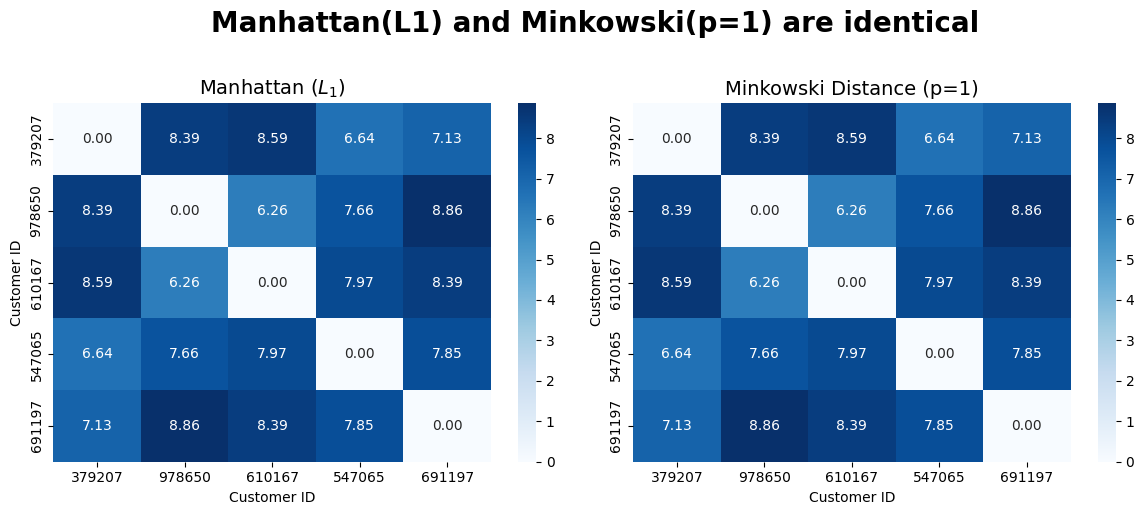

In [74]:
# Comparative plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


data1 = df_dist_manhattan.iloc[:5, :5]
data2 = df_dist_minkowski_1.iloc[:5, :5]


sns.heatmap(data1, ax=axes[0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0].set_title('Manhattan ($L_1$)', fontsize=14)

sns.heatmap(data2, ax=axes[1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1].set_title('Minkowski Distance (p=1)', fontsize=14)

fig.suptitle('Manhattan(L1) and Minkowski(p=1) are identical', fontsize=20, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

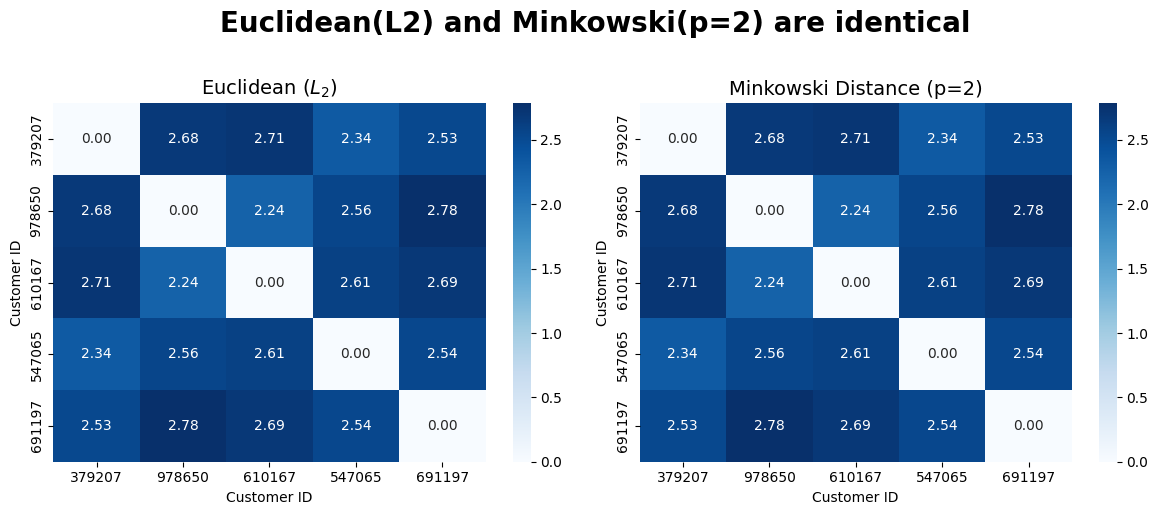

In [61]:
# Comparative plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


data1 = df_dist_euclidean.iloc[:5, :5]
data2 = df_dist_minkowski_2.iloc[:5, :5]


sns.heatmap(data1, ax=axes[0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0].set_title('Euclidean ($L_2$)', fontsize=14)

sns.heatmap(data2, ax=axes[1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1].set_title('Minkowski Distance (p=2)', fontsize=14)

fig.suptitle('Euclidean(L2) and Minkowski(p=2) are identical', fontsize=20, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

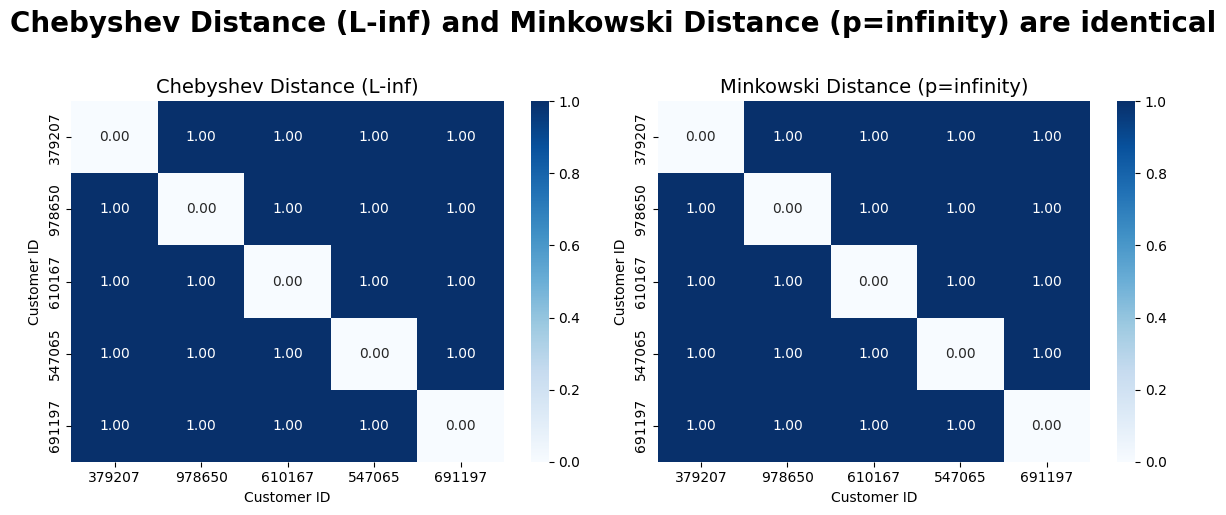

In [69]:
# Comparative plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


data1 = df_dist_chebyshev.iloc[:5, :5]
data2 = df_dist_minkowski_inf.iloc[:5, :5]


sns.heatmap(data1, ax=axes[0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0].set_title('Chebyshev Distance (L-inf)', fontsize=14)

sns.heatmap(data2, ax=axes[1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1].set_title('Minkowski Distance (p=infinity)', fontsize=14)

fig.suptitle('Chebyshev Distance (L-inf) and Minkowski Distance (p=infinity) are identical', fontsize=20, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

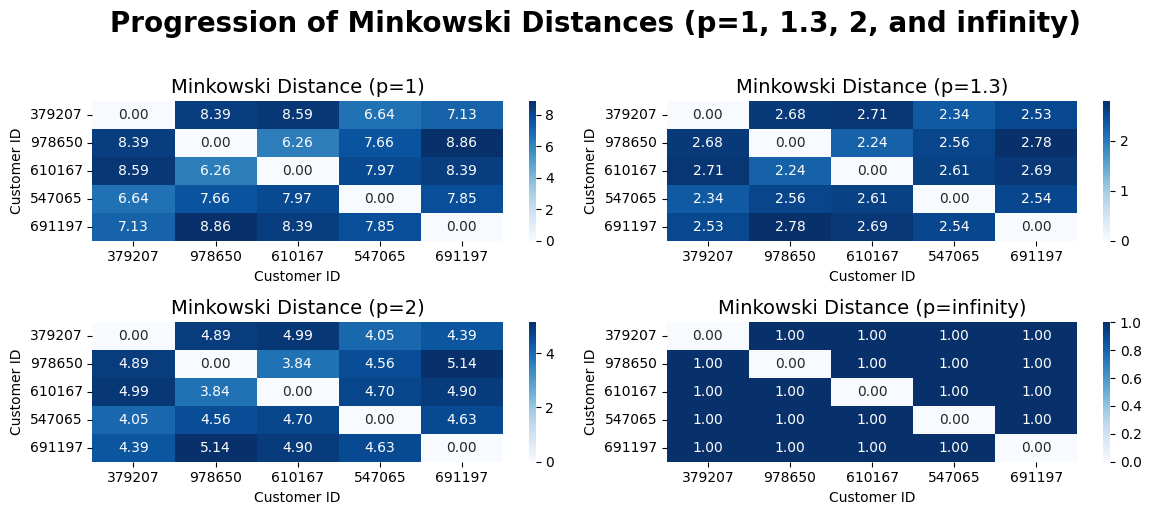

In [72]:
# Comparative plots
fig, axes = plt.subplots(2, 2, figsize=(12, 5))


data1 = df_dist_minkowski_1.iloc[:5, :5]
data2 = df_dist_minkowski_2.iloc[:5, :5]
data3 = df_dist_minkowski_13.iloc[:5, :5]
data4 = df_dist_minkowski_inf.iloc[:5, :5]


sns.heatmap(data1, ax=axes[0, 0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0, 0].set_title('Minkowski Distance (p=1)', fontsize=14)

sns.heatmap(data2, ax=axes[0, 1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0, 1].set_title('Minkowski Distance (p=1.3)', fontsize=14)

sns.heatmap(data3, ax=axes[1, 0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1, 0].set_title('Minkowski Distance (p=2)', fontsize=14)

sns.heatmap(data4, ax=axes[1, 1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1, 1].set_title('Minkowski Distance (p=infinity)', fontsize=14)

# Global Title
fig.suptitle('Progression of Minkowski Distances (p=1, 1.3, 2, and infinity)', fontsize=20, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

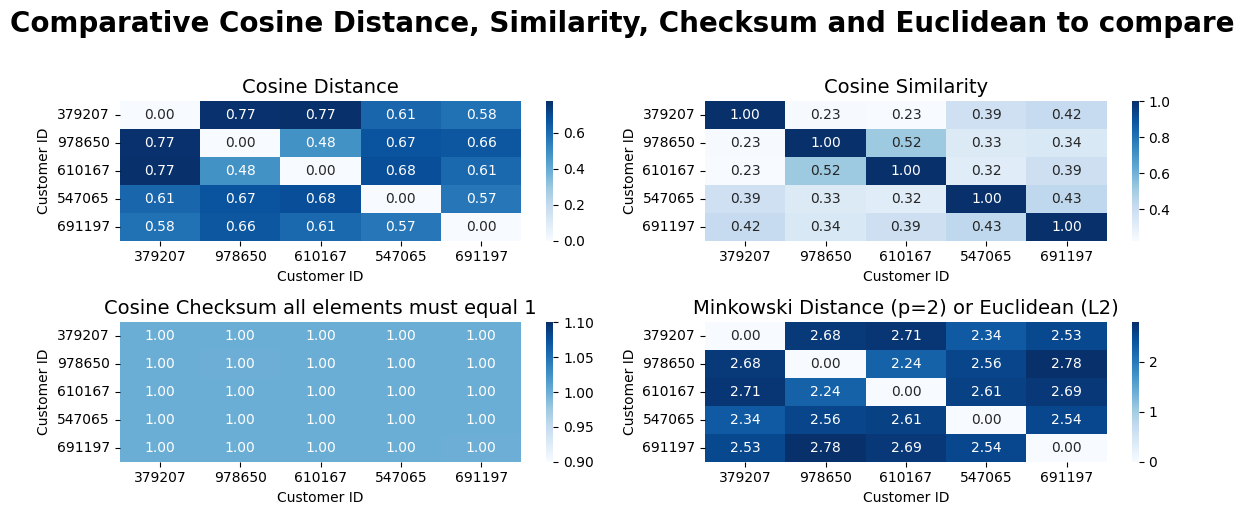

In [73]:
# Comparative plots
fig, axes = plt.subplots(2, 2, figsize=(12, 5))


data1 = df_dist_cosine_dist.iloc[:5, :5]
data2 = df_sim_cosine_sim.iloc[:5, :5]
data3 = df_checksum.iloc[:5, :5]
data4 = df_dist_euclidean.iloc[:5, :5]


sns.heatmap(data1, ax=axes[0, 0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0, 0].set_title('Cosine Distance', fontsize=14)

sns.heatmap(data2, ax=axes[0, 1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[0, 1].set_title('Cosine Similarity', fontsize=14)

sns.heatmap(data3, ax=axes[1, 0], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1, 0].set_title('Cosine Checksum all elements must equal 1', fontsize=14)

sns.heatmap(data4, ax=axes[1, 1], cmap='Blues', annot=True, fmt=".2f", cbar=True)
axes[1, 1].set_title('Minkowski Distance (p=2) or Euclidean (L2)', fontsize=14)

# Global Title
fig.suptitle('Comparative Cosine Distance, Similarity, Checksum and Euclidean to compare', fontsize=20, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

# End of Part 1